# Fase 3: resultados en test

Esta es la evaluación final. Los entrenamientos se lanzan con `python scripts/fase3_resultados.py` (unos 15 minutos con 10 núcleos) y los resultados se guardan en `results/fase3_*.csv`. Este notebook solo los lee.

**Qué se ha entrenado.** Cada mercado y algoritmo se entrena de nuevo con **10 semillas nuevas** (de la 100 a la 109), distintas de las del ajuste. Si se reutilizaran aquellas, el resultado saldría inflado, porque la configuración se eligió precisamente porque les fue bien. Hay dos versiones de cada agente:

- **Ajustado:** la configuración elegida en la fase 2, con 4000 episodios.
- **Sin ajustar:** la configuración de partida de la fase 1 (α = 1/n^0,6, γ = 0,9, 10 intervalos, ε→0,01 en el 70%), con 2000 episodios.

**Cómo se evalúa.** Todos los agentes y las cuatro estrategias de referencia se prueban en las **mismas 100 series de test** de cada mercado, que no se habían usado hasta ahora. Cada fila de un agente de RL resume 10 × 100 = 1000 episodios de test; el aleatorio también se repite con 10 semillas.

**Qué se mide.**

- **Rentabilidad:** cuánto gana o pierde el capital en el episodio completo, en %. La métrica principal es la mediana, porque en el mercado de ciclo unas pocas series disparan la media.
- **Sharpe:** rentabilidad dividida entre volatilidad, anualizada como si cada paso fuera un día.
- **Drawdown:** la mayor caída del capital desde un máximo anterior.
- **Supera a B&H:** en qué porcentaje de episodios el agente acaba con más capital que buy & hold en la misma serie.
- **Convergencia:** el primer episodio a partir del cual la mediana en validación ya no se aleja más de un 10% (o de 1 punto) de su valor final. Se da la mediana entre semillas, en episodios y en segundos de entrenamiento.
- **Tiempos:** sin contar las evaluaciones. Se midieron con 10 entrenamientos a la vez, así que sirven para comparar unos con otros, no como tiempos absolutos.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FixedLocator, FuncFormatter, NullFormatter

import rl_trader
from rl_trader.agents import Discretizador
from rl_trader.baselines import BASELINES
from rl_trader.evaluation import SEMILLA_VALIDACION, evaluar, generar_series, ic_bootstrap_pareado
from rl_trader.plots import (AZUL, EJE, FONDO, GRIS, NARANJA, NOMBRES_MERCADO, SECUENCIAL, TINTA_2,
                             aplicar_estilo, compacto, corto)
from rl_trader.prices import GENERADORES

aplicar_estilo()
ROOT = Path(rl_trader.__file__).resolve().parent.parent
RESULTADOS, FIGURAS = ROOT / "results", ROOT / "figures"
MERCADOS = list(NOMBRES_MERCADO)

test = pd.read_csv(RESULTADOS / "fase3_test_por_serie.csv")
runs = pd.read_csv(RESULTADOS / "fase3_entrenamientos.csv", dtype={"politica": str})
curvas = (pd.read_csv(RESULTADOS / "fase3_curvas.csv", dtype={"politica": str})
          .merge(runs[["run", "mercado", "agente", "seed"]], on="run"))
test["log_capital"] = np.log1p(test["retorno_pct"] / 100)

AGENTES = ["aleatorio", "buy_and_hold", "momentum", "contrarian",
           "qlearning (sin ajustar)", "sarsa (sin ajustar)", "qlearning", "sarsa"]
ETIQUETAS = {"aleatorio": "Aleatorio", "buy_and_hold": "Buy & hold", "momentum": "Momentum",
             "contrarian": "Contrarian", "qlearning (sin ajustar)": "Q-learning sin ajustar",
             "sarsa (sin ajustar)": "Sarsa sin ajustar", "qlearning": "Q-learning", "sarsa": "Sarsa"}
COLORES = {"qlearning": AZUL, "sarsa": NARANJA, "qlearning (sin ajustar)": AZUL, "sarsa (sin ajustar)": NARANJA}
print(f"{runs.shape[0]} entrenamientos, {test.shape[0]} episodios de test")

160 entrenamientos, 21200 episodios de test


## 1. Tabla de resultados

Una fila por mercado y agente. `mediana_%` y `media_%` son la rentabilidad en test; `mediana_semillas` dice entre qué valores se mueve la mediana según la semilla; las columnas de convergencia y de entrenamiento solo existen para los agentes de RL.

In [2]:
bh = test[test.agente == "buy_and_hold"].set_index(["mercado", "serie"])["log_capital"].rename("log_bh")
test = test.join(bh, on=["mercado", "serie"])


def resumen(d):
    por_semilla = d.groupby("seed")["retorno_pct"].median()
    return pd.Series({
        "mediana_%": d["retorno_pct"].median(),
        "media_%": d["retorno_pct"].mean(),
        "sharpe": d["sharpe"].mean(),
        "drawdown_%": d["max_drawdown_pct"].mean(),
        "operaciones": d["operaciones"].mean(),
        "dentro_%": d["tiempo_dentro_pct"].mean(),
        "supera_BH_%": 100 * (d["log_capital"] > d["log_bh"] + 1e-12).mean(),
        "mediana_semillas": f"{corto(por_semilla.min())} a {corto(por_semilla.max())}" if len(por_semilla) > 1 else "",
    })


tabla = test.groupby(["mercado", "agente"]).apply(resumen)
entrenamiento = runs.groupby(["mercado", "agente"]).agg(
    episodios=("n_episodios", "first"),
    convergencia_ep=("episodio_convergencia", "median"),
    convergencia_s=("segundos_convergencia", "median"),
    entrenamiento_s=("segundos", "mean"))
tabla = tabla.join(entrenamiento)
orden = pd.MultiIndex.from_product([MERCADOS, AGENTES], names=["mercado", "agente"])
tabla = tabla.reindex(orden).reset_index()
tabla.to_csv(RESULTADOS / "fase3_tabla.csv", index=False)

with pd.option_context("display.width", 250):
    print(tabla.to_string(index=False, na_rep="", float_format=corto))

  mercado                  agente  mediana_%  media_%  sharpe  drawdown_%  operaciones  dentro_%  supera_BH_% mediana_semillas  episodios  convergencia_ep  convergencia_s  entrenamiento_s
    ciclo               aleatorio        456     1776     1.3        78.4          165      50.1         13.6        377 a 601                                                             
    ciclo            buy_and_hold       3425      24K     1.9        88.6          1.0       100          0.0                                                                              
    ciclo                momentum        48K     229K     3.1        60.8         92.3      55.2         97.0                                                                              
    ciclo              contrarian      -92.9    -80.1    -0.7        94.6         91.9      44.8          0.0                                                                              
    ciclo qlearning (sin ajustar)        46K     274K     3.

## 2. Capital final por agente

Con cuánto dinero acaba cada agente, como múltiplo del capital inicial (×2 quiere decir que lo duplica). El punto es la mediana de todos los episodios de test y la línea va del percentil 25 al 75. El eje es logarítmico y la línea vertical marca el capital inicial (×1).

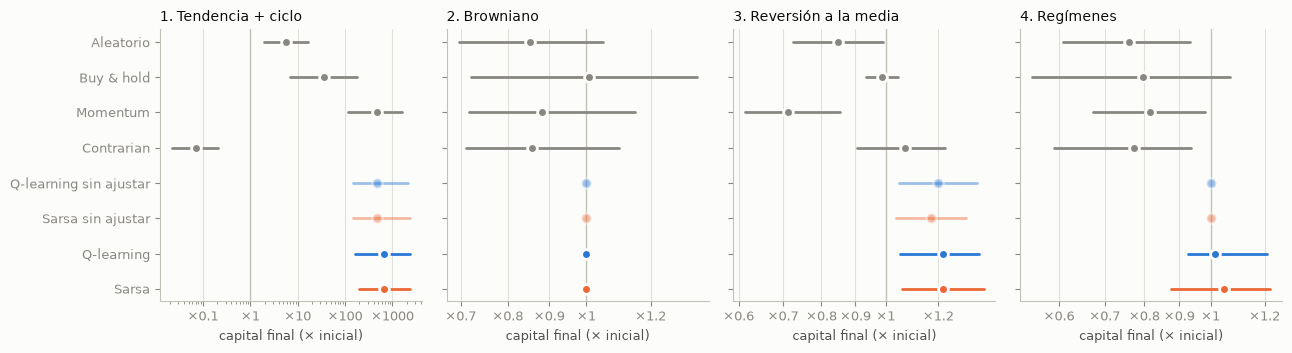

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6), sharey=True)
y = np.arange(len(AGENTES))[::-1]
for ax, m in zip(axes, MERCADOS):
    ax.axvline(1, color=EJE, lw=1)
    for yi, agente in zip(y, AGENTES):
        multiplo = np.exp(test[(test.mercado == m) & (test.agente == agente)]["log_capital"])
        p25, p50, p75 = np.percentile(multiplo, [25, 50, 75])
        color = COLORES.get(agente, GRIS)
        alfa = 0.45 if "sin ajustar" in agente else 1.0
        ax.plot([p25, p75], [yi, yi], color=color, alpha=alfa, lw=2, solid_capstyle="round")
        ax.plot(p50, yi, "o", ms=7, color=color, alpha=alfa, mec=FONDO, mew=2)
    ax.set_xscale("log")
    # Marcas legibles en escala log, también cuando el rango es estrecho
    lo, hi = ax.get_xlim()
    if hi / lo > 30:
        candidatas = [0.001, 0.01, 0.1, 1, 10, 100, 1000, 10000, 100000]
    else:
        candidatas = [0.5, 0.6, 0.7, 0.8, 0.9, 1, 1.2, 1.5, 2, 3]
    ax.xaxis.set_major_locator(FixedLocator([c for c in candidatas if lo <= c <= hi]))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"×{x:g}"))
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_title(NOMBRES_MERCADO[m], loc="left")
    ax.set_xlabel("capital final (× inicial)")
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(y, [ETIQUETAS[a] for a in AGENTES])
fig.tight_layout()
fig.savefig(FIGURAS / "fase3_capital_final.png", dpi=200)
plt.show()

## 3. ¿Son significativas las diferencias?

Que un agente tenga mejor mediana que otro no basta: la diferencia podría deberse al azar de las series. Para comprobarlo, cada comparación usa las mismas 100 series de test y compara, serie a serie, el capital final de los dos. Para un agente de RL, en cada serie se promedia el logaritmo del capital final de sus 10 semillas.

- **No operar** es quedarse siempre fuera (el capital final es el inicial). Es el rival natural cuando no hay nada que aprender.
- **Ratio** es cuántas veces más capital acaba teniendo el primero que el segundo, en media geométrica, con su intervalo de confianza del 95% calculado por bootstrap. Por ejemplo, 1,20 [1,05; 1,37] significa que el primero acaba con un 20% más de capital. Si el intervalo no incluye el 1, la diferencia es significativa.
- **Mejor regla** es la estrategia de referencia con más log-capital medio en test.

In [4]:
por_serie = test.groupby(["mercado", "agente", "serie"])["log_capital"].mean()
reglas = ["aleatorio", "buy_and_hold", "momentum", "contrarian"]
filas = []
for m in MERCADOS:
    s = por_serie.loc[m]
    mejor_regla = max(reglas, key=lambda r: s.loc[r].mean())
    mejor_rl = max(["qlearning", "sarsa"], key=lambda r: s.loc[r].mean())
    comparaciones = [
        ("Q-learning vs Sarsa", "qlearning", "sarsa"),
        (f"{ETIQUETAS[mejor_rl]} vs Buy & hold", mejor_rl, "buy_and_hold"),
        (f"{ETIQUETAS[mejor_rl]} vs {ETIQUETAS[mejor_regla]} (mejor regla)", mejor_rl, mejor_regla),
        (f"{ETIQUETAS[mejor_rl]} vs no operar", mejor_rl, "fuera"),
        ("Q-learning: ajustado vs sin ajustar", "qlearning", "qlearning (sin ajustar)"),
        ("Sarsa: ajustado vs sin ajustar", "sarsa", "sarsa (sin ajustar)"),
    ]
    for nombre, x, z in comparaciones:
        if "mejor regla" in nombre and mejor_regla == "buy_and_hold":
            continue  # ya está en la fila anterior
        valores = [np.zeros(len(s.loc[x])) if a == "fuera" else s.loc[a].to_numpy() for a in (x, z)]
        d, inf, sup = ic_bootstrap_pareado(*valores)
        filas.append({"mercado": m, "comparación": nombre, "ratio": np.exp(d),
                      "IC 95%": f"[{np.exp(inf):.2f}; {np.exp(sup):.2f}]",
                      "significativa": "sí" if (inf > 0 or sup < 0) else "no"})
comparaciones = pd.DataFrame(filas)
comparaciones.to_csv(RESULTADOS / "fase3_comparaciones.csv", index=False)
with pd.option_context("display.width", 200):
    print(comparaciones.to_string(index=False, float_format=lambda v: f"{v:.2f}"))

  mercado                          comparación  ratio           IC 95% significativa
    ciclo                  Q-learning vs Sarsa   0.98     [0.97; 1.00]            sí
    ciclo                  Sarsa vs Buy & hold  18.11   [12.89; 25.20]            sí
    ciclo      Sarsa vs Momentum (mejor regla)   1.37     [1.15; 1.61]            sí
    ciclo                   Sarsa vs no operar 648.56 [463.91; 896.15]            sí
    ciclo  Q-learning: ajustado vs sin ajustar   1.19     [1.02; 1.38]            sí
    ciclo       Sarsa: ajustado vs sin ajustar   1.18     [1.00; 1.37]            sí
browniano                  Q-learning vs Sarsa   0.98     [0.98; 0.99]            sí
browniano                  Sarsa vs Buy & hold   1.01     [0.93; 1.10]            no
browniano                   Sarsa vs no operar   1.00     [1.00; 1.00]            no
browniano  Q-learning: ajustado vs sin ajustar   0.98     [0.98; 0.99]            sí
browniano       Sarsa: ajustado vs sin ajustar   1.00     [1.00; 

## 4. Curvas de aprendizaje (configuraciones ajustadas)

Cada 200 episodios de entrenamiento se prueba la política en las 100 series de validación. La curva es la mediana de la rentabilidad: la línea es la media de las 10 semillas y la banda, su desviación típica. El punto marca la mediana del episodio de convergencia. La línea gris es buy & hold en esas mismas series.

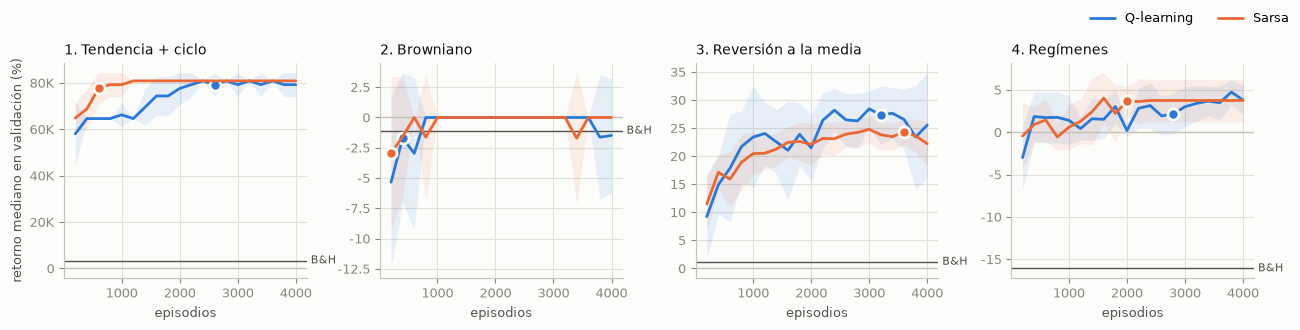

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.3))
for ax, m in zip(axes, MERCADOS):
    val = generar_series(GENERADORES[m], 100, SEMILLA_VALIDACION)
    bh_val = evaluar(BASELINES["buy_and_hold"](), val)["retorno_pct"].median()
    ax.axhline(0, color=EJE, lw=1)
    ax.axhline(bh_val, color=TINTA_2, lw=1)
    ax.text(1.0, bh_val, " B&H", transform=ax.get_yaxis_transform(), va="center", color=TINTA_2, fontsize=8)
    for agente in ("qlearning", "sarsa"):
        d = curvas[(curvas.mercado == m) & (curvas.agente == agente)]
        g = d.groupby("episodio")["retorno_mediana_pct"]
        media, sd = g.mean(), g.std()
        ax.fill_between(media.index, media - sd, media + sd, color=COLORES[agente], alpha=0.1, lw=0)
        ax.plot(media.index, media.values, color=COLORES[agente], label=ETIQUETAS[agente])
        conv = runs[(runs.mercado == m) & (runs.agente == agente)]["episodio_convergencia"].median()
        ep = media.index[np.argmin(np.abs(media.index - conv))]
        ax.plot(ep, media.loc[ep], "o", ms=8, color=COLORES[agente], mec=FONDO, mew=2)
    ax.set_title(NOMBRES_MERCADO[m], loc="left")
    ax.set_xlabel("episodios")
    ax.yaxis.set_major_formatter(FuncFormatter(compacto))
axes[0].set_ylabel("retorno mediano en validación (%)")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", ncol=2)
fig.tight_layout(rect=(0, 0, 1, 0.92))
fig.savefig(FIGURAS / "fase3_curvas.png", dpi=200)
plt.show()

## 5. Políticas aprendidas (configuraciones ajustadas)

Para cada estado, qué fracción de las 10 semillas acaba con una política que está **dentro** del mercado:

- Si no tiene el activo, "dentro" significa que lo compra.
- Si ya lo tiene, "dentro" significa que no lo vende.

En el eje vertical están los cortes de la tendencia (cuánto se aleja el precio de su media de los últimos 6 pasos). Si una semilla no compra en ningún estado, nunca llega a los estados con el activo, y esos estados cuentan como fuera.

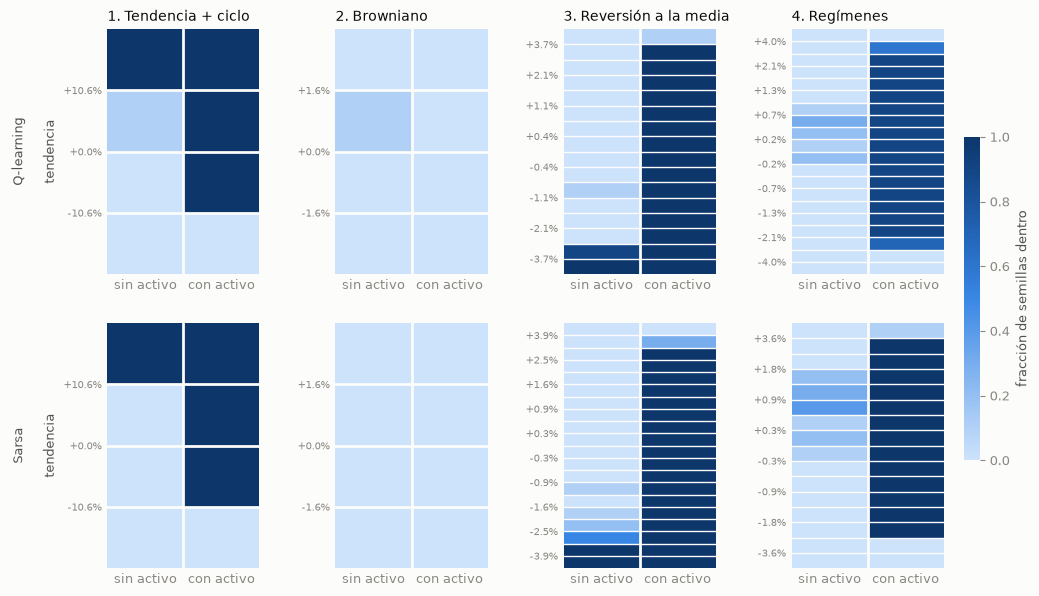

In [6]:
def efectiva(cadena):
    v = np.array(list(cadena), dtype=int)
    if not v[0::2].any():
        v[1::2] = 0
    return v


fig, axes = plt.subplots(2, 4, figsize=(13, 7), gridspec_kw={"wspace": 0.5})
for i, agente in enumerate(("qlearning", "sarsa")):
    for j, m in enumerate(MERCADOS):
        r = runs[(runs.mercado == m) & (runs.agente == agente)]
        n = int(r["n_intervalos"].iloc[0])
        dentro = np.mean([efectiva(p) for p in r["politica"]], axis=0).reshape(n, 2)
        ax = axes[i, j]
        im = ax.imshow(dentro, cmap=SECUENCIAL, vmin=0, vmax=1, aspect="auto", origin="lower")
        cortes = Discretizador.ajustar(GENERADORES[m], n_intervalos=n).cortes
        paso = 1 if n <= 10 else 2
        posiciones = np.arange(1, n)[::-1][::paso][::-1]
        ax.set_yticks(posiciones - 0.5, [f"{100 * cortes[k - 1]:+.1f}%" for k in posiciones], fontsize=7)
        ax.set_xticks([0, 1], ["sin activo", "con activo"])
        ax.tick_params(length=0)
        ax.grid(False)
        for lado in ax.spines.values():
            lado.set_visible(False)
        for k in range(1, n):
            ax.axhline(k - 0.5, color=FONDO, lw=1 if n > 10 else 2)
        ax.axvline(0.5, color=FONDO, lw=2)
        if i == 0:
            ax.set_title(NOMBRES_MERCADO[m], loc="left")
    axes[i, 0].set_ylabel(f"{ETIQUETAS[agente]}\n\ntendencia")
cb = fig.colorbar(im, ax=axes, shrink=0.6, pad=0.02)
cb.set_label("fracción de semillas dentro", color=TINTA_2)
cb.outline.set_visible(False)
fig.savefig(FIGURAS / "fase3_politicas.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Conclusiones

Las cifras son medianas de la rentabilidad en test. Los "×" comparan el capital final de dos agentes (cuántas veces más acaba teniendo uno que el otro), con su intervalo de confianza del 95%, como en la sección 3.

**Tendencia + ciclo: momentum.**

- Sarsa (+68.000%) y Q-learning (+65.000%) ganan a la regla de momentum (+48.000%), con un ratio de ×1,37 [1,15; 1,61] en el caso de Sarsa. Y lo consiguen operando un tercio de las veces (31–33 operaciones frente a 92).
- La clave es la histéresis que aprenden: solo compran cuando la tendencia es muy positiva y no venden hasta que es muy negativa.
- Buy & hold se queda en +3.400%.
- El ajuste mejora el capital final ×1,18–1,19 frente a la versión sin ajustar (en Sarsa, justo en el límite de ser significativo).

**Browniano: no hay nada que aprender, y los agentes se dan cuenta.**

- Sarsa y las dos versiones sin ajustar no operan nunca (0%).
- Ninguna diferencia con buy & hold es significativa (×1,01 [0,93; 1,10]).
- Q-learning ajustado tiene una semilla que opera y pierde. Con γ = 0, Q-learning y Sarsa actualizan igual, así que es cosa del azar de esa semilla, no del algoritmo.
- Hay que recordar que esta configuración se eligió entre muchas que empataban a 0 en validación. Su α fijo de 0,01 es más sensible al ruido que el α que va bajando de la fase 1.

**Reversión a la media: contrarian selectivo.**

- Los agentes ajustados (+22%) ganan a la regla contrarian (+6,9%, ×1,14 [1,09; 1,20]), a buy & hold (−1,1%) y a no operar (×1,22).
- **En test, el ajuste no se nota:** frente a la versión sin ajustar, ×1,01 y ×1,03, que no son significativos. La mejora que se veía en validación (26% frente a 19–21%) era sobre todo sesgo de selección: se eligió la mejor de 35 configuraciones con solo 3 semillas, y la que sale mejor en una muestra pequeña suele serlo en parte por suerte.
- Los agentes ajustados operan menos (22–29 operaciones frente a 46–48), pero pasan más tiempo dentro.

**Regímenes: la ventaja que se veía en validación se mantiene en test, aunque es pequeña.**

- Q-learning gana a no operar por ×1,06 [1,03; 1,10]; Sarsa, por ×1,05 [1,00; 1,09], justo en el límite.
- Frente a buy & hold (−20%) y momentum (−18%) la diferencia es amplia: ×1,38 y ×1,30.
- La política aprendida usa el **tamaño de la tendencia como pista de la volatilidad**: compra cuando la tendencia es positiva pero moderada, aguanta mientras se mueva dentro de ±2% y sale ante movimientos extremos.
- El resultado cambia bastante de una semilla a otra (medianas del −2% al +9%), y el drawdown medio es del 18–23%.
- Esto es justo lo que no conseguía la configuración de la fase 1, que casi no operaba. Según la etapa A del ajuste, lo que más pesa es un α fijo y pequeño, que promedia mucho ruido, y un γ alto, que hace que el agente valore mantener la posición. La etapa B muestra además que tener más intervalos ayuda a separar las tendencias moderadas de las extremas.

**Q-learning frente a Sarsa.** En ningún mercado hay una diferencia que se pueda atribuir al algoritmo.

- En ciclo y browniano, con γ = 0, son el mismo algoritmo. Sus diferencias (×0,98) vienen del α elegido o del azar de las semillas.
- En reversión y regímenes, con γ > 0, las diferencias no son significativas.
- Encaja con cómo es el problema: el agente no influye en la tendencia, solo en su posición. Además, una acción de exploración cuesta como mucho una comisión del 0,1%, así que no hay un "acantilado" como en Cliff Walking que lleve a Sarsa a aprender algo más prudente.

**Convergencia.** Mediana entre semillas del episodio a partir del cual la validación se queda a menos del 10% de su valor final:

| Mercado | Q-learning | Sarsa | Comentario |
|---|---|---|---|
| Ciclo | 2600 episodios (24 s) | 600 episodios (4 s) | La diferencia viene del α elegido: constante 0,001 frente a 1/n^0,6 |
| Browniano | 200–500 episodios (2–5 s) | 200–500 episodios (2–5 s) | |
| Reversión | 3300–3700 episodios (unos 30 s) | 3300–3700 episodios (unos 30 s) | |
| Regímenes | 2000–2900 episodios (16–28 s) | 2000–2900 episodios (16–28 s) | |

En general, las configuraciones ajustadas tardan más en converger que las sin ajustar (400–1900 episodios), porque su α es más pequeño. A cambio, acaban mejor en ciclo y en regímenes.

**Limitaciones.**

- El agente solo ve la tendencia de los últimos 6 pasos y su posición. Le falta, por ejemplo, saber cuánto se ha alejado el precio de su media a largo plazo (clave en reversión) y la volatilidad (clave en regímenes).
- Los mercados son simulados con parámetros fijos, y la comisión también es fija.
- En el mercado de ciclo, el ruido del 10% por paso da rentabilidades poco realistas.
- Las diferencias pequeñas entre configuraciones son menores que lo que varía el resultado entre semillas: el ajuste solo es fiable cuando las diferencias son grandes.